# Eksplorasi data kerusakan bangunan

Tujuan analisis ini adalah mengenali data sebelum membuat model klasifikasi lima tingkat kerusakan.
Saya mulai dari struktur data, memeriksa kualitasnya, kemudian melihat distribusi dan hubungan fitur.
Setiap pemeriksaan diikuti penjelasan mengenai keputusan pemodelan.

Data yang digunakan adalah `train.csv`, `test.csv`, `sample_submission.csv`, dan `metadata.csv` dari kompetisi.
Target train masih berbentuk `Grade 1` sampai `Grade 5`; file prediksi nantinya memakai angka 1–5.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'scripts').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts').exists(), 'Jalankan dari folder proyek atau notebooks.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / 'data'
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 2026
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)
plt.rcParams['figure.dpi'] = 110

## 1. Membaca data dan mengenali kolom

Saya memeriksa beberapa baris pertama, ukuran tabel, tipe data, dan isi metadata.
Walaupun ID wilayah terbaca sebagai angka, maknanya adalah kategori lokasi.

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
metadata = pd.read_csv(DATA_DIR / 'metadata.csv')
target = 'damage_grade'
print('Ukuran train:', train.shape)
print('Ukuran test:', test.shape)
print('Ukuran template:', sample.shape)
display(train.head())
train.info()
display(metadata)

Ukuran train: (533465, 17)
Ukuran test: (228629, 16)
Ukuran template: (228629, 2)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (...,Number
8,land_surface_condition,Surface condition of the land in which the bui...,Categorical
9,foundation_type,Type of foundation used in the building,Categorical


In [3]:
metadata_columns = set(metadata['Variable'].str.strip())
actual_columns = set(train.columns)
print('Kolom metadata yang tidak ada di train:', sorted(metadata_columns - actual_columns))
print('Kolom train yang tidak tercantum di metadata:', sorted(actual_columns - metadata_columns))
assert set(train.drop(columns=target).columns) == set(test.columns)
assert sample.columns.tolist() == ['building_id', 'damage_grade']
assert test['building_id'].equals(sample['building_id'])
print('Skema fitur dan urutan ID template cocok.')

Kolom metadata yang tidak ada di train: ['has_superstructure_adobe_mud', 'has_superstructure_bamboo', 'has_superstructure_cement_mortar_brick', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_mud_mortar_stone', 'has_superstructure_other', 'has_superstructure_rc_engineered', 'has_superstructure_rc_non_engineered', 'has_superstructure_stone_flag', 'has_superstructure_timber']
Kolom train yang tidak tercantum di metadata: ['superstructure']
Skema fitur dan urutan ID template cocok.


Metadata menjelaskan beberapa flag `has_superstructure_*`, sedangkan CSV aktual memiliki satu kolom
`superstructure`. Karena itu, kode harus mengikuti skema CSV aktual; saya tidak membuat kolom flag
yang seolah-olah tersedia. Analisis menggunakan kolom yang tersedia pada CSV aktual.

## 2. Missing value dan duplikat

Saya menghitung nilai null pada seluruh data. Heatmap menggunakan sampel tetap agar grafik tetap terbaca;
kesimpulan jumlah missing value berasal dari tabel lengkap, bukan hanya heatmap.

,train_null,train_null_pct,test_null,test_null_pct
building_id,0,0.0,0.0,0.0
district_id,0,0.0,0.0,0.0
vdcmun_id,0,0.0,0.0,0.0
ward_id,0,0.0,0.0,0.0
count_floors_pre_eq,0,0.0,0.0,0.0
age_building,0,0.0,0.0,0.0
plinth_area_sq_ft,0,0.0,0.0,0.0
height_ft_pre_eq,0,0.0,0.0,0.0
land_surface_condition,0,0.0,0.0,0.0
foundation_type,0,0.0,0.0,0.0


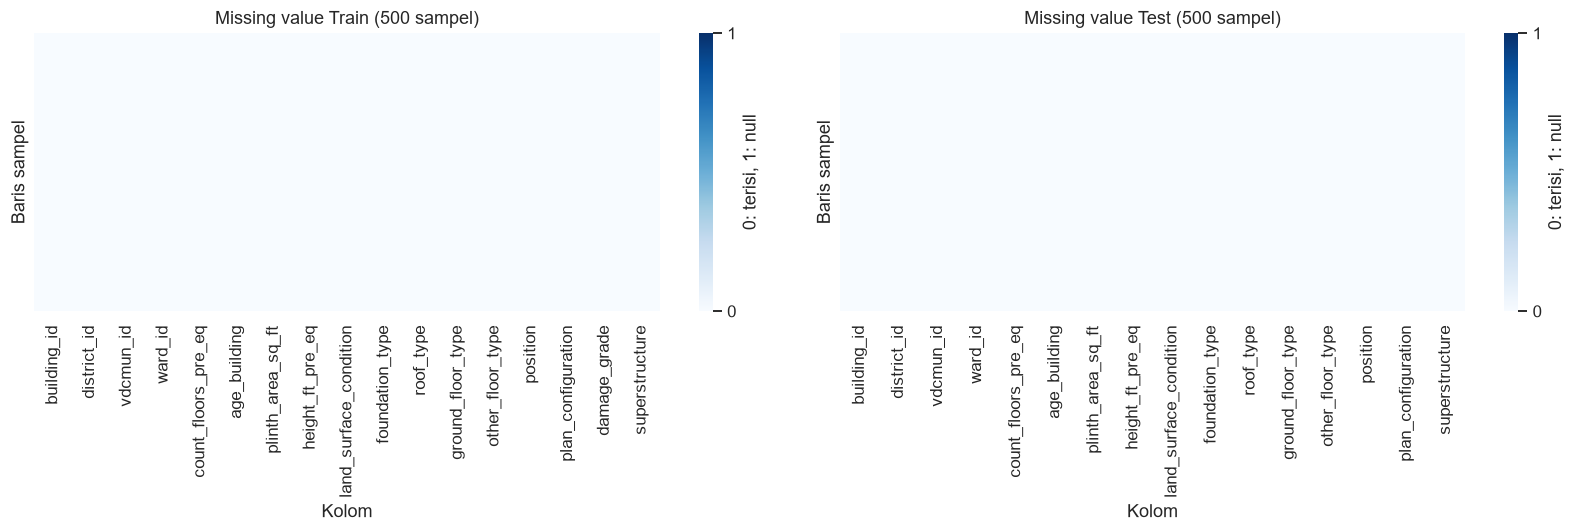

Total null train: 0
Total null test: 0


In [4]:
quality = pd.concat({
    'train_null': train.isnull().sum(),
    'train_null_pct': train.isnull().mean().mul(100),
    'test_null': test.isnull().sum(),
    'test_null_pct': test.isnull().mean().mul(100),
}, axis=1)
display(quality)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, frame) in zip(axes, [('Train', train), ('Test', test)]):
    missing_sample = frame.sample(min(500, len(frame)), random_state=SEED).isnull()
    sns.heatmap(missing_sample, ax=ax, cmap='Blues', vmin=0, vmax=1, yticklabels=False,
                cbar_kws={'ticks': [0, 1], 'label': '0: terisi, 1: null'})
    ax.set_title(f'Missing value {name} (500 sampel)')
    ax.set_xlabel('Kolom')
    ax.set_ylabel('Baris sampel')
plt.tight_layout()
fig.savefig(FIGURES / 'missing_values.png', bbox_inches='tight')
plt.show()
print('Total null train:', int(train.isnull().sum().sum()))
print('Total null test:', int(test.isnull().sum().sum()))

In [5]:
display(pd.DataFrame({
    'dataset': ['train', 'test'],
    'baris_duplikat': [train.duplicated().sum(), test.duplicated().sum()],
    'id_duplikat': [train.building_id.duplicated().sum(), test.building_id.duplicated().sum()],
}))
id_overlap = train['building_id'].isin(test['building_id']).sum()
print('ID train yang juga terdapat di test:', int(id_overlap))
assert train.building_id.is_unique and test.building_id.is_unique
assert id_overlap == 0

,dataset,baris_duplikat,id_duplikat
0,train,0,0
1,test,0,0


ID train yang juga terdapat di test: 0


Train dan test tidak memiliki null. Heatmap yang seragam sesuai dengan hasil pemeriksaan tersebut.
Namun, tidak adanya null belum menjamin semua nilai valid. Nilai sentinel seperti umur `999`
perlu diperiksa terpisah. Imputer tetap dipasang di pipeline untuk nilai kosong yang muncul setelah
pembersihan dan untuk inferensi berikutnya.

## 3. Apakah kelas seimbang?

Jumlah dan persentase tiap kelas membantu menentukan split dan metrik evaluasi.
Saya memakai urutan Grade 1 hingga Grade 5 agar perbandingannya mudah dibaca.

,jumlah,persentase
damage_grade,,
Grade 1,55170,10.34
Grade 2,61080,11.45
Grade 3,95488,17.90
Grade 4,128691,24.12
Grade 5,193036,36.19


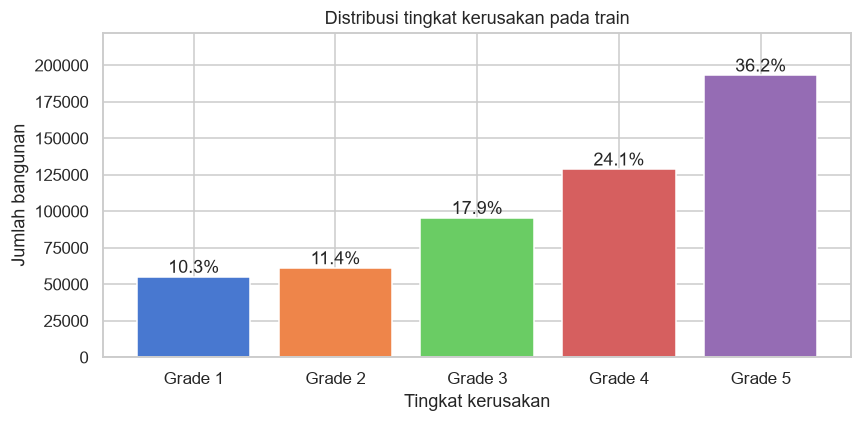

Rasio kelas terbesar terhadap terkecil: 3.50 kali


In [6]:
grades = [f'Grade {i}' for i in range(1, 6)]
counts = train[target].value_counts().reindex(grades)
distribution = pd.DataFrame({'jumlah': counts, 'persentase': counts / len(train) * 100})
display(distribution.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(distribution.index, distribution['jumlah'], color=sns.color_palette('muted', 5))
for i, (_, row) in enumerate(distribution.iterrows()):
    ax.text(i, row['jumlah'], f"{row['persentase']:.1f}%", ha='center', va='bottom')
ax.set(title='Distribusi tingkat kerusakan pada train', xlabel='Tingkat kerusakan', ylabel='Jumlah bangunan')
ax.margins(y=.15)
plt.tight_layout()
fig.savefig(FIGURES / 'class_distribution.png', bbox_inches='tight')
plt.show()
print(f'Rasio kelas terbesar terhadap terkecil: {counts.max() / counts.min():.2f} kali')

Grade 5 paling banyak dan Grade 1 paling sedikit. Distribusi ini tidak seimbang, sehingga akurasi saja
dapat menutupi kelemahan pada kelas yang lebih kecil. Saya menggunakan split stratified dan Macro F1,
kemudian memeriksa precision, recall, serta F1 setiap kelas. Ketidakseimbangan tidak otomatis berarti
harus melakukan oversampling; keputusan itu perlu diuji pada data pengembangan.

## 4. Nilai sentinel dan rentang fitur numerik

Saya memeriksa umur `999`, umur negatif, jumlah lantai nol/negatif, serta luas dan tinggi yang tidak positif.
Pemeriksaan ini bersifat deskriptif; nilai ekstrem yang masih mungkin valid tidak langsung dihapus.

In [7]:
numeric = ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
display(train[numeric].describe(percentiles=[.01, .25, .5, .75, .99]).T)
checks = {}
for name, frame in [('train', train), ('test', test)]:
    checks[name] = {
        'umur_999': frame.age_building.eq(999).sum(),
        'umur_negatif': frame.age_building.lt(0).sum(),
        'lantai_tidak_positif': frame.count_floors_pre_eq.le(0).sum(),
        'luas_tidak_positif': frame.plinth_area_sq_ft.le(0).sum(),
        'tinggi_tidak_positif': frame.height_ft_pre_eq.le(0).sum(),
    }
display(pd.DataFrame(checks))
clean_numeric = train[numeric].copy()
clean_numeric['age_building'] = clean_numeric['age_building'].replace(999, np.nan)

,count,mean,std,min,1%,25%,50%,75%,99%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,1.0,2.0,2.0,2.0,4.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,1.0,9.0,16.0,27.0,90.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,120.0,280.0,358.0,470.0,1222.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,6.0,12.0,16.0,18.0,32.0,99.0


,train,test
umur_999,2198,946
umur_negatif,0,0
lantai_tidak_positif,0,0
luas_tidak_positif,0,0
tinggi_tidak_positif,0,0


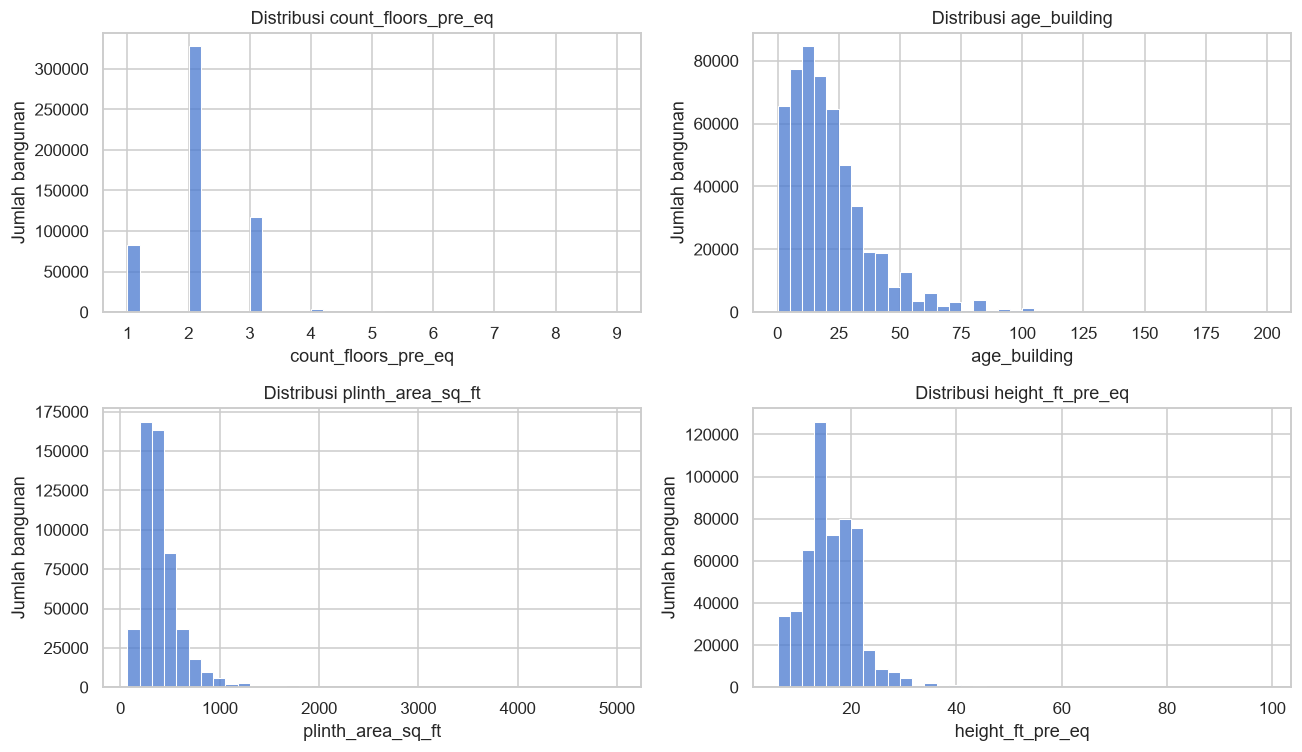

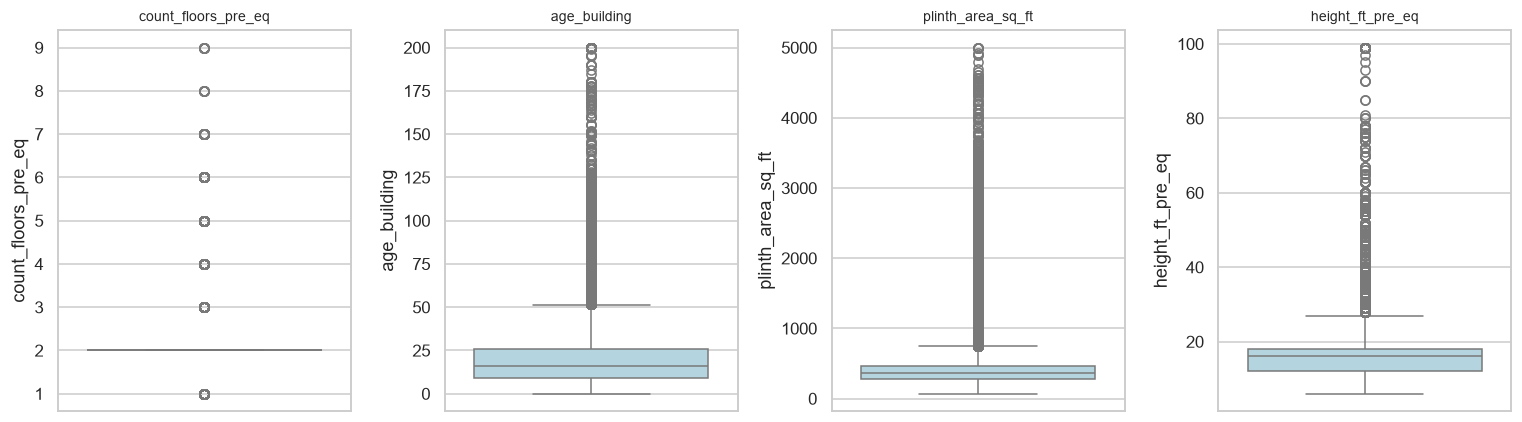

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for column, ax in zip(numeric, axes.ravel()):
    sns.histplot(clean_numeric[column], bins=40, ax=ax)
    ax.set_title(f'Distribusi {column}')
    ax.set_ylabel('Jumlah bangunan')
plt.tight_layout()
fig.savefig(FIGURES / 'numeric_histograms.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for column, ax in zip(numeric, axes):
    sns.boxplot(y=clean_numeric[column], ax=ax, color='lightblue')
    ax.set_title(column, fontsize=9)
plt.tight_layout()
fig.savefig(FIGURES / 'numeric_boxplots.png', bbox_inches='tight')
plt.show()

Pemeriksaan menemukan 2.198 umur `999` pada train dan 946 pada test. Tidak ditemukan umur negatif, lantai tidak positif, luas tidak positif, atau tinggi tidak positif pada pemeriksaan ini.

Umur `999` ditandai sebagai umur tidak diketahui dalam preprocessing yang sudah ada.
Saya mempertahankan indikator `age_is_unknown`, lalu mengganti nilai tersebut menjadi missing
sebelum imputasi median yang hanya dipelajari dari training. Histogram dan boxplot memperlihatkan
rentang serta kemencengan distribusi; data ekstrem tetap dipertahankan agar tidak membuang bangunan
yang mungkin valid tanpa dasar yang cukup.

## 5. Hubungan antarfitur dan tingkat kerusakan

Korelasi dihitung untuk empat ukuran numerik bangunan. ID bangunan dan kode wilayah dikeluarkan
karena nilai angkanya bukan ukuran kontinu. Korelasi ini membantu eksplorasi, bukan bukti sebab-akibat.

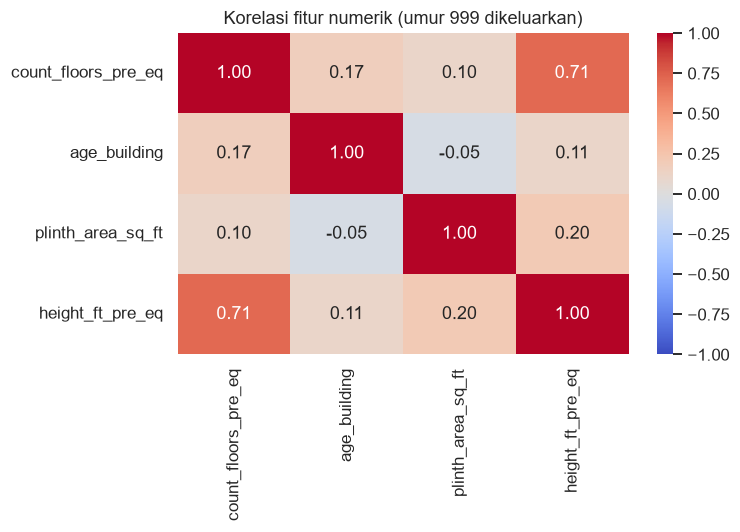

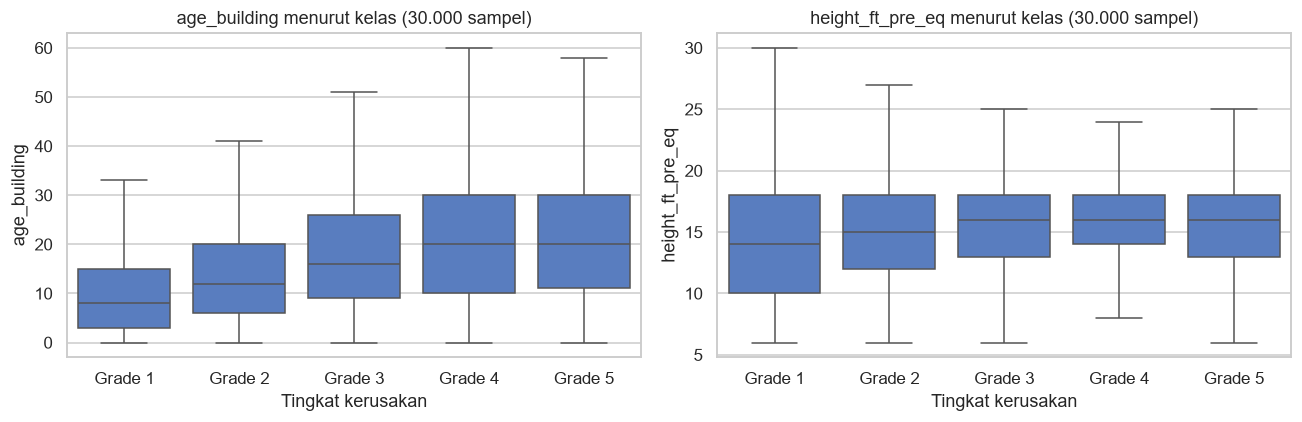

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(clean_numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korelasi fitur numerik (umur 999 dikeluarkan)')
plt.tight_layout()
fig.savefig(FIGURES / 'numeric_correlation.png', bbox_inches='tight')
plt.show()

plot_data = train.sample(min(30000, len(train)), random_state=SEED).copy()
plot_data['age_building'] = plot_data['age_building'].replace(999, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ['age_building', 'height_ft_pre_eq']):
    sns.boxplot(data=plot_data, x=target, y=column, order=grades, showfliers=False, ax=ax)
    ax.set_title(f'{column} menurut kelas (30.000 sampel)')
    ax.set_xlabel('Tingkat kerusakan')
plt.tight_layout()
fig.savefig(FIGURES / 'numeric_by_grade.png', bbox_inches='tight')
plt.show()

Jumlah lantai dan tinggi memiliki korelasi positif sekitar 0,71. Hal ini masuk akal karena bangunan bertingkat biasanya lebih tinggi. Boxplot umur menurut target memperlihatkan perbedaan distribusi, tetapi rentang antarkelas masih tumpang tindih, sehingga satu fitur saja belum cukup untuk membedakan kerusakan.

## 6. Fitur kategorikal

Saya menampilkan banyaknya kategori, distribusi kategori umum, dan proporsi target pada jenis fondasi.
Kategori langka dan kategori test yang tidak ditemukan pada train perlu ditangani saat inferensi.

,kategori_train,kategori_test,kategori_test_baru
district_id,11,11,0
vdcmun_id,110,110,0
ward_id,945,945,0
land_surface_condition,3,3,0
foundation_type,5,5,0
roof_type,3,3,0
ground_floor_type,5,5,0
other_floor_type,4,4,0
position,4,4,0
plan_configuration,10,10,0


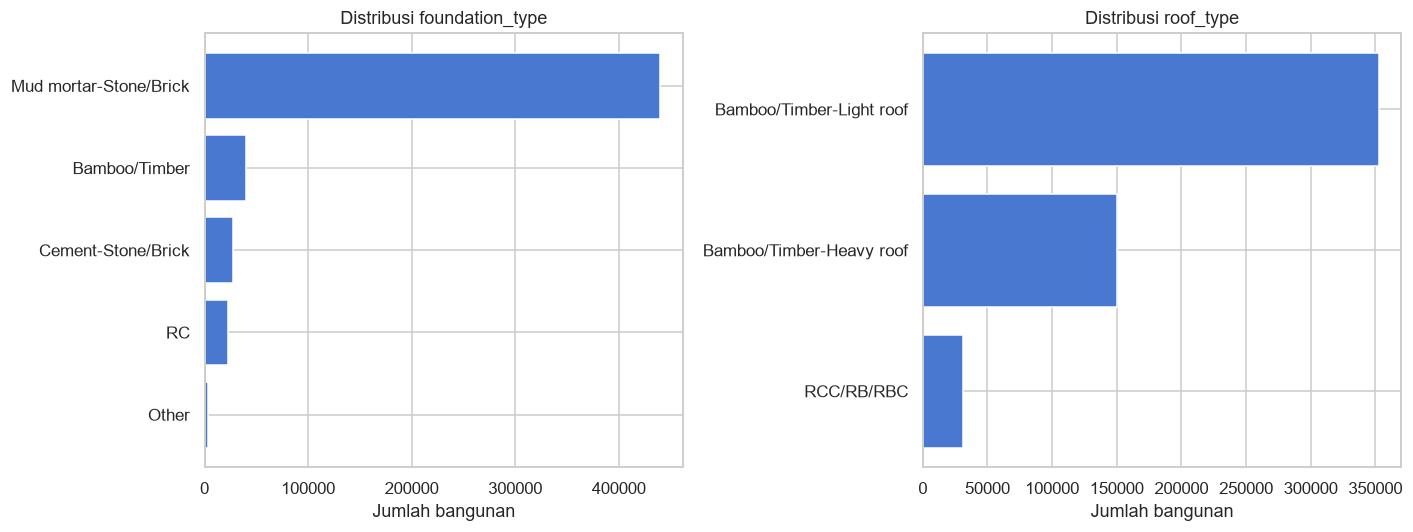

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
foundation_type,,,,,
Bamboo/Timber,0.301,0.233,0.232,0.144,0.091
Cement-Stone/Brick,0.296,0.226,0.180,0.143,0.155
Mud mortar-Stone/Brick,0.047,0.089,0.179,0.268,0.417
Other,0.297,0.089,0.097,0.153,0.365
RC,0.595,0.268,0.098,0.022,0.016


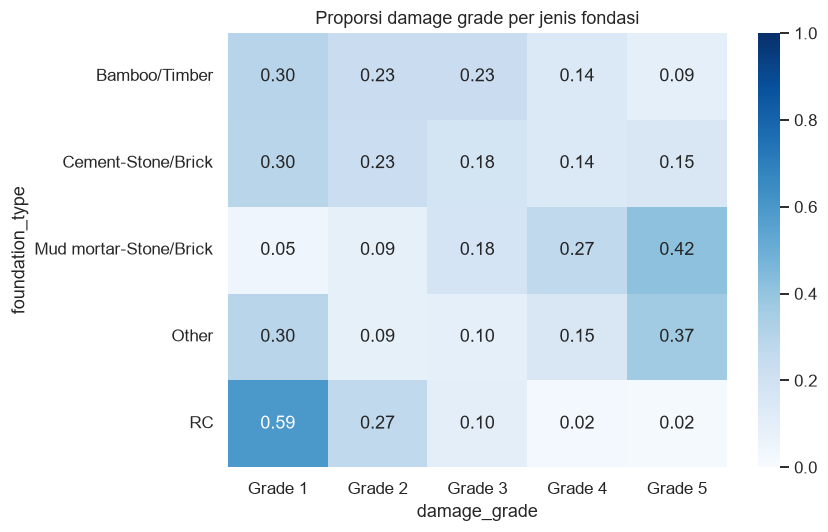

In [10]:
categorical = ['district_id', 'vdcmun_id', 'ward_id', 'land_surface_condition', 'foundation_type',
               'roof_type', 'ground_floor_type', 'other_floor_type', 'position',
               'plan_configuration', 'superstructure']
category_summary = pd.DataFrame({
    'kategori_train': train[categorical].nunique(),
    'kategori_test': test[categorical].nunique(),
    'kategori_test_baru': [test[c].drop_duplicates().isin(train[c].unique()).eq(False).sum()
                          for c in categorical],
})
display(category_summary)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, column in zip(axes, ['foundation_type', 'roof_type']):
    frequencies = train[column].value_counts().head(10)
    ax.barh(frequencies.index.astype(str), frequencies.values)
    ax.invert_yaxis()
    ax.set_title(f'Distribusi {column}')
    ax.set_xlabel('Jumlah bangunan')
plt.tight_layout()
fig.savefig(FIGURES / 'categorical_distributions.png', bbox_inches='tight')
plt.show()

foundation_rates = pd.crosstab(train.foundation_type, train[target], normalize='index').reindex(columns=grades)
display(foundation_rates.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(foundation_rates, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Proporsi damage grade per jenis fondasi')
plt.tight_layout()
fig.savefig(FIGURES / 'foundation_grade_heatmap.png', bbox_inches='tight')
plt.show()

Pada data ini, sekitar 59,5% bangunan dengan fondasi RC berada pada Grade 1, sedangkan sekitar 42% bangunan dengan fondasi Mud mortar-Stone/Brick berada pada Grade 5. Perbedaan ini menunjukkan bahwa jenis fondasi layak diperiksa sebagai fitur, tetapi tidak membuktikan pengaruh sebab-akibat.

Proporsi kelas berbeda menurut fondasi, tetapi pola tersebut dapat dipengaruhi lokasi dan karakteristik
bangunan lainnya. Karena itu, saya menggunakan fitur tersebut bersama-sama dalam model.
Tabel target di sini hanya untuk eksplorasi; encoding target di model dihitung ulang secara cross-fit
pada training, bukan disalin dari tabel EDA ini.

## 7. Keputusan sebelum pemodelan

- Gunakan empat fitur numerik dan kategori bangunan/lokasi sesuai skema aktual.
- Tangani umur tidak diketahui dengan indikator dan imputasi di dalam pipeline.
- Pertahankan proporsi lima kelas melalui split stratified; gunakan Macro F1 dan metrik per kelas.
- Gunakan kategori yang dipelajari pada training; kategori baru tidak boleh mengubah vocabulary model.
- Gunakan fitur turunan ID sebagai sinyal pola survei.
- Jangan memakai label evaluation atau test untuk belajar preprocessing, tuning, atau kalibrasi.

Notebook berikut menjalankan pemodelan berdasarkan keputusan ini. Seluruh gambar disimpan di `reports/figures/`.